In [1]:
import DecisionTree
import pandas as pd
from nltk import ConfusionMatrix
from sklearn.compose import ColumnTransformer

df = pd.read_csv("./ia_tweets.csv")

df.head()

,ID,text,polarity,favorite_count,retweet_count,user_followers_count,user_friends_count,user_favourites_count,user_statuses_count,user_verified,user_has_extended_profile,user_is_translator,user_protected,user_default_profile
0,0,Comentaba en una charla sobre IA que el proble...,N,21,7,15936,2395,66945,68578,0,1,0,0,0
1,1,"@alvaropons Eso es imposible. Y sí, va a gener...",N,1,0,685,851,169490,128555,0,1,0,0,1
2,2,@alvaropons Lo disruptivo es que tras años de ...,NEU,1,0,685,851,169490,128555,0,1,0,0,1
3,3,"@alvaropons ¿""Prohibición del uso comercial de...",N,0,0,4877,538,6123,3156,0,1,0,0,0
4,4,@santoroydonoso Cómo se está estudiando prohib...,NEU,0,0,15936,2395,66945,68578,0,1,0,0,0


In [2]:
df.dtypes

ID                           int64
text                           str
polarity                       str
favorite_count               int64
retweet_count                int64
user_followers_count         int64
user_friends_count           int64
user_favourites_count        int64
user_statuses_count          int64
user_verified                int64
user_has_extended_profile    int64
user_is_translator           int64
user_protected               int64
user_default_profile         int64
dtype: object

In [3]:
from langdetect import detect, DetectorFactory

DetectorFactory.seed = 0

df['idioma'] = df['text'].apply(detect)

df = df[df["idioma"] == "es"]

df = df.drop(columns=["ID","user_has_extended_profile", "user_is_translator", "user_protected", "idioma"])

In [4]:
def filtrar_por_polaridad(field):
    return df[df["polarity"] == field]

cant_negativos = len(filtrar_por_polaridad("N"))
cant_neutros = len(filtrar_por_polaridad("NEU"))
cant_positivos =  len(filtrar_por_polaridad("P"))

print('Cantidad de tweets: ', len(df))
print('Tweets Negativos: ', cant_negativos, ', Neutros' , cant_neutros,', Positivos', cant_positivos)

# Cantidad de datos desbalanceada, se tiene mucho mas datos neutros que negativos o positivos.

Cantidad de tweets:  3660
Tweets Negativos:  551 , Neutros 2417 , Positivos 692


In [5]:
cantidad_na = df.isna().sum()
print(cantidad_na)

#(cantidad_negativos_columna("favorite_count"))

# No hay nulls o valores

text                     0
polarity                 0
favorite_count           0
retweet_count            0
user_followers_count     0
user_friends_count       0
user_favourites_count    0
user_statuses_count      0
user_verified            0
user_default_profile     0
dtype: int64


In [6]:
cantidad_negativos = (df.select_dtypes(include='number') < 0).sum()
print(cantidad_negativos)

favorite_count           0
retweet_count            0
user_followers_count     0
user_friends_count       0
user_favourites_count    0
user_statuses_count      0
user_verified            0
user_default_profile     0
dtype: int64


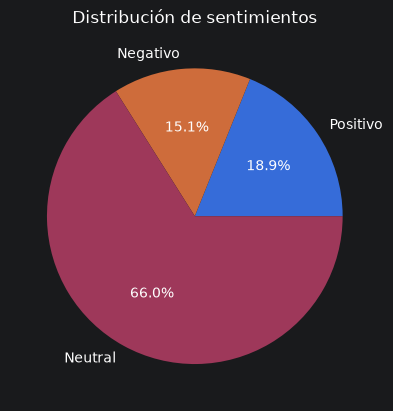

In [7]:
import matplotlib.pyplot as plt

# Datos
clases = ['Positivo', 'Negativo', 'Neutral']
cantidades = [cant_positivos, cant_negativos, cant_neutros]

# Crear gráfico
plt.pie(cantidades, labels=clases, autopct='%1.1f%%')
plt.title('Distribución de sentimientos')
plt.show()

4.1519125683060105
2243
0


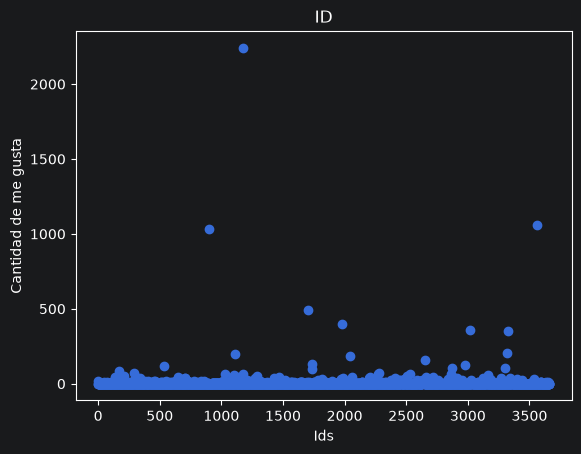

In [8]:
print(df["favorite_count"].mean())
print(df["favorite_count"].max())
print(df["favorite_count"].min())

plt.scatter(range(0,len(df)), df['favorite_count'])

plt.xlabel('Ids')
plt.ylabel('Cantidad de me gusta')
plt.title('ID')

plt.show()

0.9606557377049181
502
0


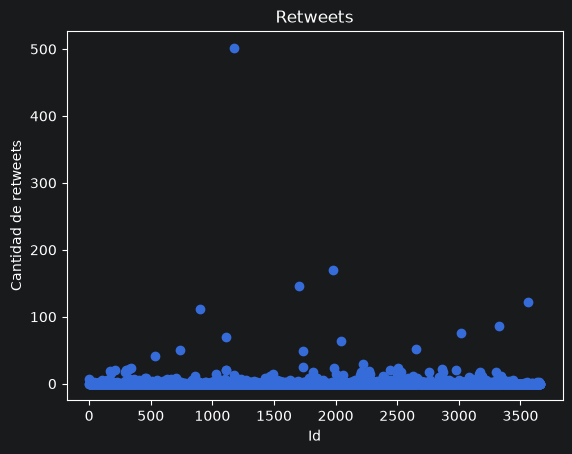

In [9]:
print(df["retweet_count"].mean())
print(df["retweet_count"].max())
print(df["retweet_count"].min())

plt.scatter(range(0,len(df)), df['retweet_count'])

plt.xlabel('Id')
plt.ylabel('Cantidad de retweets')
plt.title('Retweets')

plt.show()

Cantidad de tweets positivo con interaccion:  172
Cantidad de tweets negativos con interaccion:  139
Media de interacciones en positivos:  6.726878612716763
Media de interacciones en negativos:  3.8747731397459164


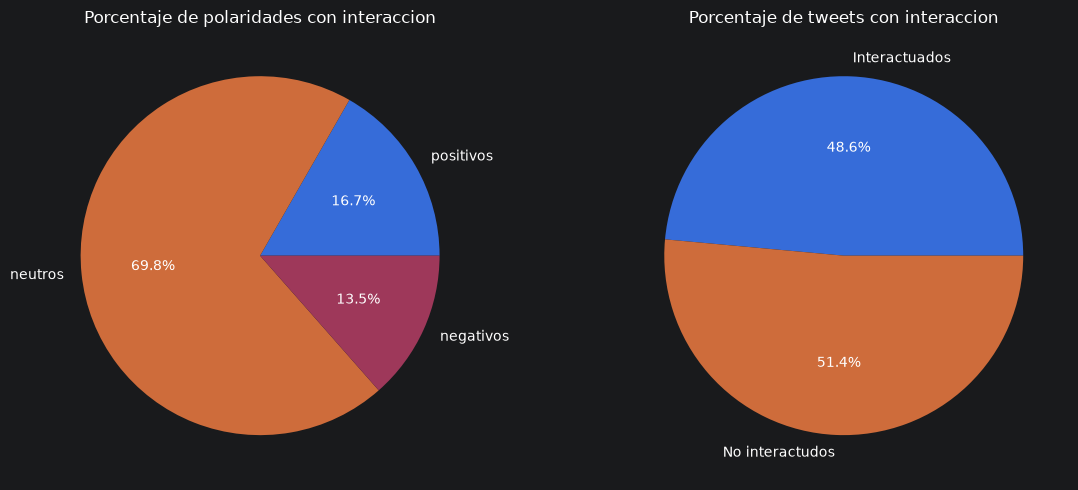

In [10]:
df['tweet_interactions'] = df['favorite_count'] + df['retweet_count']

tweets_con_interaccion = (df['tweet_interactions'] > 0).sum()
tweets_sin_interaccion = (df['tweet_interactions'] == 0).sum()

positivos_con_interaccion = (df[df['polarity'] == 'P']['tweet_interactions'] > 1).sum()
neutros_con_interaccion = (df[df['polarity'] == 'NEU']['tweet_interactions'] > 1).sum()
negativos_con_interaccion = (df[df['polarity'] == 'N']['tweet_interactions'] > 1).sum()
interaccion_positivos_media = df[df['polarity'] == 'P']['tweet_interactions'].mean()
interaccion_negativos_media = df[df['polarity'] == 'N']['tweet_interactions'].mean()

print("Cantidad de tweets positivo con interaccion: ", positivos_con_interaccion)
print("Cantidad de tweets negativos con interaccion: ", negativos_con_interaccion)
print("Media de interacciones en positivos: ", interaccion_positivos_media)
print("Media de interacciones en negativos: ", interaccion_negativos_media)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].pie([positivos_con_interaccion, neutros_con_interaccion, negativos_con_interaccion], labels=["positivos", "neutros", "negativos"], autopct='%1.1f%%')
ax[0].set_title('Porcentaje de polaridades con interaccion')

ax[1].pie([tweets_con_interaccion, tweets_sin_interaccion],
  labels=["Interactuados", "No interactudos"], autopct='%1.1f%%')
ax[1].set_title('Porcentaje de tweets con interaccion')

plt.tight_layout()
plt.show()

In [11]:
 #text
#polarity
#favorite_count
#retweet_count
#user_followers_count
#user_friends_count
#user_favourites_count         TEST (Likes que dio)
#user_statuses_count           TEST (Publicaciones y comentarios suyos)
#user_verified                 TEST
#user_default_profile          TEST (Pagina de perfil default)

import unicodedata

def contar_emojis(texto):
    return sum(1 for caracter in str(texto) if unicodedata.category(caracter) == 'So')

df["length"] = df['text'].apply(lambda texto: len(texto.split()))
df["hashtag_count"] = df['text'].apply(lambda texto: texto.count('#'))
df["mention_count"] = df['text'].apply(lambda texto: texto.count('@'))
df["url_count"] = df['text'].apply(lambda texto: texto.count('http'))
df["interrogation_count"] = df['text'].apply(lambda texto: texto.count('?') )
df["exclamation_count"] = df['text'].apply(lambda texto: texto.count('!'))
df['emoji_count'] = df['text'].apply(contar_emojis)

# :url: :mencion:

#Campos extra
#Longitud (palabras)
#Cantidad de hashtags
#Cantidad de usuarios mencionados
#Cantidad de emojis
#Cantidad de urls
#Cantidad de signos de exclamacion/interrogacion

In [12]:
df["text"] = df["text"].str.replace(r"http\S+|www\.\S+", "URL", regex=True)
df["text"] = df["text"].str.replace(r"@\w+", "MENCION", regex=True)

print("Urls: ", df['url_count'].sum())
print("Menciones: ", df['mention_count'].sum())
df.head()

Urls:  1389
Menciones:  3039


,text,polarity,favorite_count,retweet_count,user_followers_count,user_friends_count,user_favourites_count,user_statuses_count,user_verified,user_default_profile,tweet_interactions,length,hashtag_count,mention_count,url_count,interrogation_count,exclamation_count,emoji_count
0,Comentaba en una charla sobre IA que el proble...,N,21,7,15936,2395,66945,68578,0,0,28,44,0,0,1,0,0,0
1,"MENCION Eso es imposible. Y sí, va a generar u...",N,1,0,685,851,169490,128555,0,1,1,41,0,1,0,0,0,0
2,MENCION Lo disruptivo es que tras años de deci...,NEU,1,0,685,851,169490,128555,0,1,1,39,0,1,0,0,0,0
3,"MENCION ¿""Prohibición del uso comercial de las...",N,0,0,4877,538,6123,3156,0,0,0,17,0,1,0,1,0,0
4,MENCION Cómo se está estudiando prohibir chatG...,NEU,0,0,15936,2395,66945,68578,0,0,0,39,0,1,0,1,0,0


In [13]:
import emoji
from emosent import get_emoji_sentiment_rank

def emoji_features(text):
    scores = []
    for e in emoji.emoji_list(str(text)):
        try:
            rank = get_emoji_sentiment_rank(e["emoji"])
        except KeyError:
            rank = None
        if rank is not None:
            scores.append(rank["sentiment_score"])
    if not scores:
        return 0.0, 0, 0
    return (
        sum(scores) / len(scores),
        sum(s > 0.1 for s in scores),
        sum(s < -0.1 for s in scores),
    )

df[["emoji_score", "emoji_pos", "emoji_neg"]] = df["text"].apply(
    lambda t: pd.Series(emoji_features(t))
)

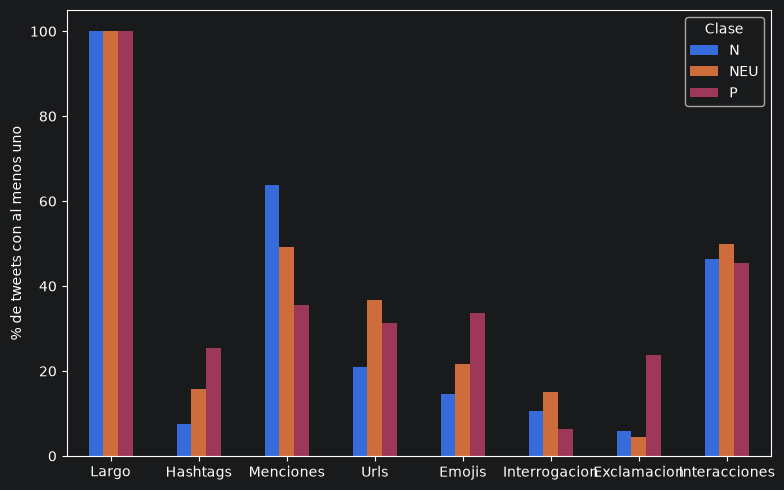

In [14]:
cols = {
    "length": "Largo",
    "hashtag_count": "Hashtags",
    "mention_count": "Menciones",
    "url_count": "Urls",
    "emoji_count": "Emojis",
    "interrogation_count": "Interrogacion",
    "exclamation_count": "Exclamacion",
    "tweet_interactions": "Interacciones"
}

# % de tweets de cada clase que tienen al menos 1 del elemento
pct = (df[list(cols)] > 0).groupby(df["polarity"]).mean() * 100
pct = pct.rename(columns=cols)

ax = pct.T.plot(kind="bar", figsize=(8, 5))
ax.set_ylabel("% de tweets con al menos uno")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
plt.legend(title="Clase")
plt.tight_layout()
plt.show()

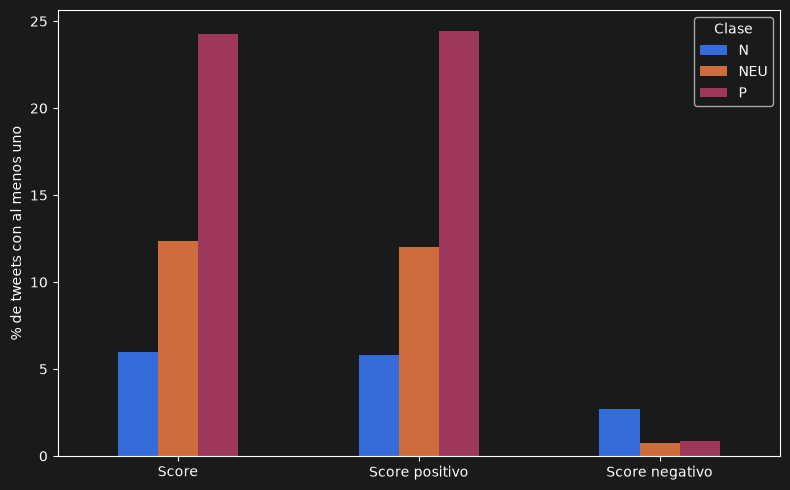

In [15]:
cols = {
    "emoji_score": "Score",
    "emoji_pos": "Score positivo",
    "emoji_neg": "Score negativo"
}

# % de tweets de cada clase que tienen al menos 1 del elemento
pct = (df[list(cols)] > 0).groupby(df["polarity"]).mean() * 100
pct = pct.rename(columns=cols)

ax = pct.T.plot(kind="bar", figsize=(8, 5))
ax.set_ylabel("% de tweets con al menos uno")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
plt.legend(title="Clase")
plt.tight_layout()
plt.show()

In [16]:
from collections import Counter

no_encontrados = Counter()
for t in df["text"]:
    for e in emoji.emoji_list(str(t)):
        if get_emoji_sentiment_rank(e["emoji"]) is None:
            no_encontrados[e["emoji"]] += 1

print(no_encontrados.most_common(15))

[('🤖', 45), ('🤔', 35), ('➡️', 34), ('🤣', 31), ('🧵', 31), ('🧠', 15), ('⬇️', 14), ('👉🏻', 14), ('🔗', 14), ('🗣️', 13), ('🗣', 11), ('‼️', 11), ('🤓', 10), ('🤭', 10), ('👉🏼', 10)]


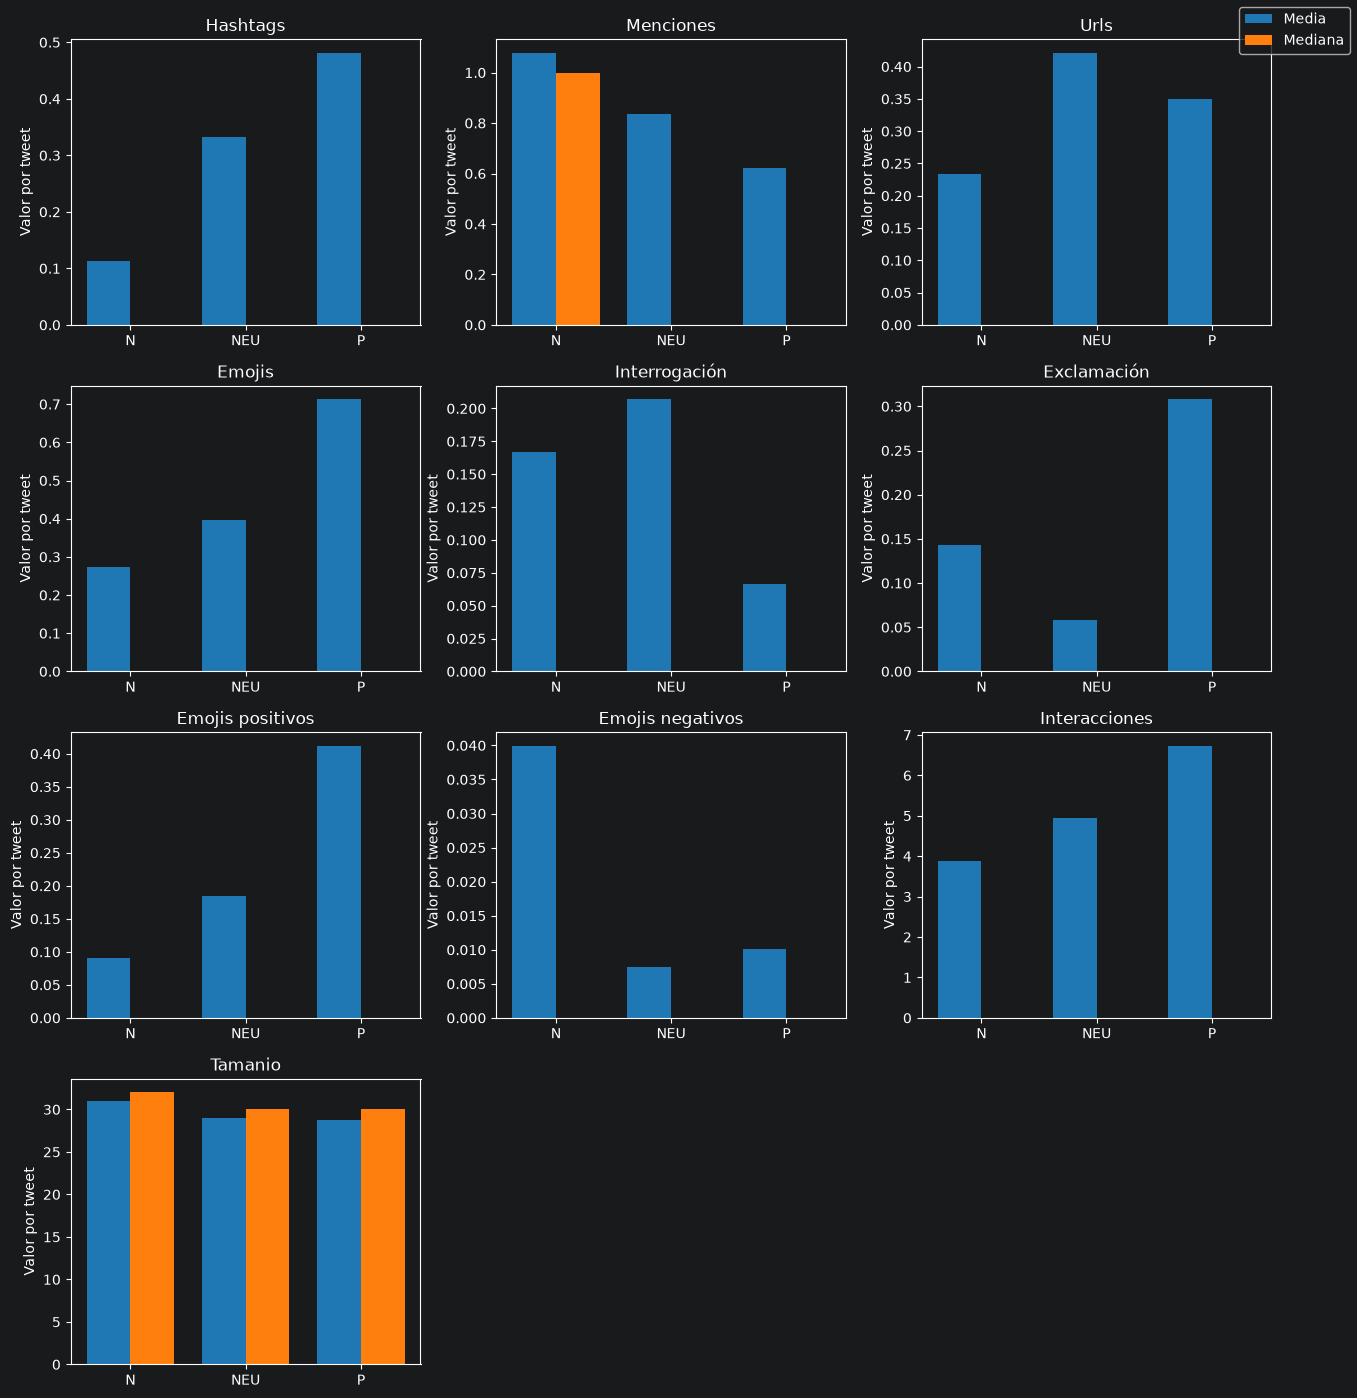

In [17]:
import numpy as np
import matplotlib.pyplot as plt

nombres = {
    "hashtag_count": "Hashtags",
    "mention_count": "Menciones",
    "url_count": "Urls",
    "emoji_count": "Emojis",
    "interrogation_count": "Interrogación",
    "exclamation_count": "Exclamación",
    "emoji_pos": "Emojis positivos",
    "emoji_neg": "Emojis negativos",
    "tweet_interactions": "Interacciones",
    "length": "Tamanio"
}

grupos = df.groupby("polarity")[list(nombres)]
medias = grupos.mean()
medianas = grupos.median()

clases = medias.index.tolist()
x = np.arange(len(clases))
ancho = 0.38

n = len(nombres)
ncols = 3
nrows = -(-n // ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 3.5 * nrows))
axes = axes.flatten()

for ax, (col, titulo) in zip(axes, nombres.items()):
    ax.bar(x - ancho / 2, medias[col], ancho, label="Media", color="tab:blue")
    ax.bar(x + ancho / 2, medianas[col], ancho, label="Mediana", color="tab:orange")
    ax.set_title(titulo)
    ax.set_xticks(x)
    ax.set_xticklabels(clases)
    ax.set_ylabel("Valor por tweet")

for ax in axes[n:]:
    ax.axis("off")

# una sola leyenda para toda la figura
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right")

plt.tight_layout(rect=[0, 0, 0.95, 1])
plt.show()

In [18]:
df = df.drop(columns=["emoji_score"])

In [19]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["polarity"])
y = df["polarity"]

# 60% para train y 40% para test y validacion
X_train, X_test_val, y_train, y_test_val = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

# Segunda división: separar test y validación
X_test, X_val, y_test, y_val = train_test_split(
    X_test_val, y_test_val,
    test_size=0.5,
    random_state=42,
    stratify=y_test_val
)

print(len(X_train)/len(df))

0.6


In [20]:
from sklearn.base import BaseEstimator, TransformerMixin
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
import string

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt_tab')
stop_words = set(stopwords.words('spanish'))

import string
import nltk
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from sklearn.base import BaseEstimator, TransformerMixin

PUNCT = set(string.punctuation) | set("¿¡«»“”‘’…")

# Palabras que NO se eliminan aunque estén en la lista de stopwords
KEEP = {"no", "ni", "sin", "nunca", "tampoco", "nada", "contra", "muy", "pero", "más", "menos"}
STOP_WORDS = set(stopwords.words("spanish")) - KEEP


class TextCleaner(BaseEstimator, TransformerMixin):
    def __init__(self, method=None, ngram_range=(1, 1), remove_stopwords=True):
        self.method = method                      # None, "stem" o "lemma"
        self.ngram_range = ngram_range            # (1, 1) = solo palabras sueltas
        self.remove_stopwords = remove_stopwords  # True = saca stopwords (salvo KEEP)

    def fit(self, X, y=None):
        if self.method not in (None, "stem", "lemma"):
            raise ValueError("method debe ser None, 'stem' o 'lemma'")
        return self

    def _is_valid(self, token):
        if not token.strip() or all(c in PUNCT for c in token):
            return False
        if self.remove_stopwords and token in STOP_WORDS:
            return False
        return True

    def _ngrams(self, tokens):
        n_min, n_max = self.ngram_range
        out = []
        for n in range(n_min, n_max + 1):
            out += ["_".join(tokens[i:i + n]) for i in range(len(tokens) - n + 1)]
        return out

    def transform(self, X):
        X = list(X)

        if self.method == "lemma":
            import spacy
            nlp = spacy.load("es_core_news_sm", disable=["parser", "ner"])
            token_lists = []
            for doc in nlp.pipe(X):
                # se filtra por el texto original y después se toma el lema
                token_lists.append([t.lemma_.lower() for t in doc if self._is_valid(t.text.lower())])
        else:
            token_lists = [
                [t for t in nltk.word_tokenize(text.lower(), language="spanish") if self._is_valid(t)]
                for text in X
            ]
            if self.method == "stem":
                stemmer = SnowballStemmer("spanish")
                token_lists = [[stemmer.stem(t) for t in toks] for toks in token_lists]

        return [" ".join(self._ngrams(toks)) for toks in token_lists]

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Usuario\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Usuario\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Usuario\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [21]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

cleaner = TextCleaner("lemma")

vectores = cleaner.transform(df["text"])
vectorizer_BoW = CountVectorizer()
vectorizer_Tfidf = TfidfVectorizer()


matriz_BoW = vectorizer_BoW.fit_transform(vectores)
matriz_Tfidf = vectorizer_Tfidf.fit_transform(vectores)

print(vectorizer_BoW.get_feature_names_out())
print(matriz_BoW.toarray()[0])
#print(vectores_Tfidf.shape)

['00' '000' '003' ... '𝙀𝙣𝙩𝙧𝙚𝙥𝙖𝙧𝙦𝙪𝙚𝙨' '𝙈𝙤𝙣𝙩𝙚𝙨𝙪𝙧' '𝙈𝙤𝙣𝙩𝙞𝙚𝙡']
[0 0 0 ... 0 0 0]


In [22]:
from sentence_transformers import SentenceTransformer # <- Estandar para Embeddings

class EmbeddingTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, model_name='all-MiniLM-L6-v2'):
        self.model_name = model_name
        self.model = None

    def fit(self, X, y=None):
        # Cargamos el modelo aquí para evitar errores de serialización
        if self.model is None:
            self.model = SentenceTransformer(self.model_name)
        return self

    def transform(self, X):
        # Convertimos la lista de textos en una matriz de vectores (Embeddings)
        # Esto implementa implícitamente el "Mean Pooling"
        return self.model.encode(list(X), show_progress_bar=False)


C:\Users\Usuario\Desktop\Facultad\4\cd\cienciaDeDatos\Tp_tweets\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [23]:
X_train.head()

,text,favorite_count,retweet_count,user_followers_count,user_friends_count,user_favourites_count,user_statuses_count,user_verified,user_default_profile,tweet_interactions,length,hashtag_count,mention_count,url_count,interrogation_count,exclamation_count,emoji_count,emoji_pos,emoji_neg
1468,La Agencia Española de Protección de Datos (AE...,1,0,4,7,0,173,0,1,1,19,2,0,0,0,0,0,0.0,0.0
3145,"Además, las empresas siempre necesitarán conte...",0,0,0,1,2,31,0,1,0,27,0,0,0,0,0,0,0.0,0.0
2137,MENCION Le he preguntado por Covid y su relaci...,2,0,129,295,15228,6816,0,1,2,17,0,1,0,0,0,0,0.0,0.0
3883,MENCION MENCION No se puede decir que van a se...,1,0,290,283,8406,16623,0,0,1,50,0,2,0,0,0,1,0.0,0.0
2562,MENCION MENCION MENCION Miralo desde el punto ...,0,0,20,79,374,2329,0,1,0,49,0,3,0,0,0,0,0.0,0.0


In [24]:
# ConfusionMatrixDisplay.from_predictions(y_val, y_pred)

En esta seccion se entrena el modelo con embedding:

In [25]:
# # Modelo 2: One-vs-One
# modelo_ovo = Pipeline([
#     ("pre", clone(preprocesador)),
#     ("classifier", OneVsOneClassifier(
#         DecisionTreeClassifier(
#             criterion="entropy",
#             max_depth=20,
#             random_state=42
#         )
#     ))
# ])
#
# param_grid_ovo = {
#     clave.replace(
#         "classifier__", "classifier__estimator__"
#     ): valor
#     for clave, valor in param_grid.items()
#     if clave.startswith("classifier__")
# }
#
# param_grid_ovo = {
#     'pre__text__cleaner__method': [None, 'stem', 'lemma'],
#     'pre__text__cleaner__ngram_range': [(1,1), (1,2)],
#     'pre__text__vectorizer': [CountVectorizer(), TfidfVectorizer()],
#     'classifier__estimator__max_depth': [5, 10, 20],
#     'classifier__estimator__min_samples_leaf': [1, 5, 10, 20],
#     'classifier__estimator__class_weight': [None],
# }
#
# # param_grid_ovo.update({
# #     clave: valor
# #     for clave, valor in param_grid.items()
# #     if not clave.startswith("classifier__")
# # })

Definicion de columnas de texto y numericas

In [26]:
# Columna de texto y columnas numericas
text_col = "text"
num_cols = [
    "favorite_count", "retweet_count", "user_followers_count",
    "user_friends_count", "user_favourites_count", "user_statuses_count",
    "tweet_interactions", "hashtag_count", "mention_count", "url_count", "interrogation_count",
    "exclamation_count", "length", "emoji_count"
]
passthrough_cols = ["emoji_pos", "emoji_neg"]

### Principales hiperparámetros de DecisionTreeClassifier

| Hiperparámetro | ¿Qué controla? | ¿Por qué afecta al rendimiento? |
|---|---|---|
| `max_depth` | Profundidad máxima del árbol. | Limita la complejidad y ayuda a evitar el *overfitting*. |
| `min_samples_leaf` | Mínimo de muestras que debe tener cada hoja. | Evita hojas con muy pocos ejemplos, que pueden representar patrones poco generalizables. |
| `min_samples_split` | Mínimo de muestras necesarias para dividir un nodo. | Evita divisiones cuando hay pocos ejemplos para justificarlas. |
| `criterion` | Criterio para medir la calidad de una división: `gini`, `entropy` o `log_loss`. | Influye en qué características y divisiones elige el árbol. |
| `max_features` | Cantidad de características que se consideran al buscar cada división. | Puede reducir el costo computacional y la complejidad efectiva, aunque también puede empeorar la calidad de las divisiones. |

In [30]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

# Tres variantes para la rama de texto
text_bow = Pipeline([
    ("cleaner", TextCleaner("lemma")),
    ("vectorizer", CountVectorizer()),
])
text_tfidf = Pipeline([
    ("cleaner", TextCleaner("lemma")),
    ("vectorizer", TfidfVectorizer()),
])
text_emb = EmbeddingTransformer()

# Un único preprocesador y un único pipeline
preprocesador = ColumnTransformer([
    ("text", text_bow, text_col),          # valor inicial, el grid lo reemplaza
    ("num", StandardScaler(), num_cols),
    ("raw", "passthrough", passthrough_cols),
])

pipeline = Pipeline([
    ("pre", preprocesador),
    ("classifier", DecisionTreeClassifier(random_state=42)),
])

param_grid = [
    # BoW y TF-IDF comparten los nombres de los pasos, así que sirve un solo diccionario
    {
        "pre__text": [text_bow, text_tfidf],
        "pre__text__cleaner__method": [None, "stem", "lemma"],
        "pre__text__cleaner__ngram_range": [(1, 1), (1, 2)],
        "classifier__max_depth": [5, 10, 20],
        "classifier__min_samples_leaf": [1, 5, 10, 20],
        'classifier__class_weight': [None, "balanced"],
    },
    # Embeddings: sin limpieza ni n-gramas
    {
        "pre__text": [text_emb],
        "classifier__max_depth": [5, 10, 20],
        "classifier__min_samples_leaf": [1, 5, 10, 20],
        'classifier__class_weight': [None, "balanced"],
    },
]

grid_search = GridSearchCV(pipeline, param_grid, cv=3, scoring="f1_macro", n_jobs=1, verbose=1)
grid_search.fit(X_train, y_train)

Fitting 3 folds for each of 312 candidates, totalling 936 fits


KeyboardInterrupt: 

In [29]:
print(grid_search.best_score_)
print(grid_search.best_params_)

AttributeError: 'GridSearchCV' object has no attribute 'best_score_'

In [ ]:
# Decision Tree
# Mejor F1 macro en entrenamiento: 0.4776
# Mejor configuración:
# #Mejor configuracion: {'classifier__class_weight': None, 'classifier__max_depth': 20, 'classifier__min_samples_leaf': 5, 'pre__text__cleaner__method': 'stem', 'pre__text__cleaner__ngram_range': (1, 2), 'pre__text__vectorizer': CountVectorizer()}

Entrenamiento de estrategia One versus One, usando DecisionTree como modelo, optimizando la metrica f1. Como preprocesamiento, se utiliza BoW y TfIdf.

In [ ]:
grid_search_ovo = GridSearchCV(modelo_ovo, param_grid_ovo, cv=3, scoring="f1_macro", n_jobs=1, verbose=1)
grid_search_ovo.fit(X_train, y_train)

In [ ]:
print("-" * 30)
print(f"Mejor F1 macro en entrenamiento: {grid_search_ovo.best_score_:.4f}")
print(f"Mejor configuración:\n{grid_search_ovo.best_params_}")
print("-" * 30)

#Mejor configuracion: {'classifier__estimator__criterion': 'entropy', 'classifier__estimator__max_depth': 20, 'classifier__estimator__min_samples_leaf': 1, 'classifier__estimator__min_samples_split': 5, 'pre__text__cleaner__method': 'lemma', 'pre__text__vectorizer': CountVectorizer()}

In [ ]:
from sklearn.metrics import f1_score, accuracy_score, roc_auc_score

mejor_modelo_ovo = grid_search_ovo.best_estimator_

y_pred_ovo = mejor_modelo_ovo.predict(X_val)

f1 = f1_score(
    y_val,
    y_pred_ovo,
    average="macro",
    labels=mejor_modelo_ovo.classes_
)

accuracy = accuracy_score(
    y_val,
    y_pred_ovo
)


print(f1)
print(accuracy)

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_val, y_pred_ovo)

Entrenamiento de estrategia One versus One, usando DecisionTree como modelo, optimizando la metrica f1. Como preprocesamiento, se utiliza embedding.

In [ ]:
embedding_pipeline_ovo = Pipeline([
    ("pre", preprocesador_embedding),
    ("classifier", OneVsOneClassifier(
        DecisionTreeClassifier(
            criterion="entropy",
            max_depth=20,
            random_state=42
        )
    ))
])

param_grid_embedding_ovo = {
    'classifier__estimator__max_depth': [5, 10, 20],
    'classifier__estimator__min_samples_split': [2, 5, 10]
}

In [ ]:
grid_search_embedding_ovo = GridSearchCV(embedding_pipeline_ovo, param_grid_embedding_ovo, cv=3, scoring="f1_macro", n_jobs=1, verbose=1)
grid_search_embedding_ovo.fit(X_train, y_train)

In [ ]:
print("-" * 30)
print(f"Mejor F1 macro en entrenamiento: {grid_search_embedding_ovo.best_score_:.4f}")
print(f"Mejor configuración:\n{grid_search_embedding_ovo.best_params_}")
print("-" * 30)

Entrenamiento de estrategia One versus All, usando DecisionTree como modelo, optimizando la metrica f1. Como preprocesamiento, se utiliza BoW y TfIdf.

In [ ]:
# Modelo 3: One-vs-Rest (One-vs-All)
modelo_ova = Pipeline([
    ("pre", clone(preprocesador)),
    ("classifier", OneVsRestClassifier(
        DecisionTreeClassifier(
            criterion="entropy",
            max_depth=20,
            random_state=42
        )
    ))
])

param_grid_ova = param_grid_ovo.copy()

In [ ]:
grid_search_ova = GridSearchCV(modelo_ova, param_grid_ova, cv=3, scoring="f1_macro", n_jobs=1, verbose=1)
grid_search_ova.fit(X_train, y_train)

In [ ]:
print("-" * 30)
print(f"Mejor F1 macro en entrenamiento: {grid_search_ova.best_score_:.4f}")
print(f"Mejor configuración:\n{grid_search_ova.best_params_}")
print("-" * 30)

#Mejor modelo: {'classifier__estimator__criterion': 'entropy', 'classifier__estimator__max_depth': 20, 'classifier__estimator__min_samples_leaf': 2, 'classifier__estimator__min_samples_split': 5, 'pre__text__cleaner__method': 'stem', 'pre__text__vectorizer': CountVectorizer()}

In [ ]:
mejor_modelo_ova = grid_search_ovo.best_estimator_

y_proba = mejor_modelo_ovo.predict(X_val)

f1 = f1_score(
    y_val,
    y_proba,
    average="macro",
    labels=mejor_modelo_ovo.classes_
)

print(f1)

In [ ]:
grids = {
    "Decision Tree": GridSearchCV(
        modelo_arbol, param_grid_arbol,
        cv=3, scoring="f1_macro",
        n_jobs=1, verbose=1
    ),
    "One-vs-One": GridSearchCV(
        modelo_ovo, param_grid_ovo,
        cv=3, scoring="f1_macro",
        n_jobs=1, verbose=1
    ),
    "One-vs-Rest": GridSearchCV(
        modelo_ova, param_grid_ova,
        cv=3, scoring="f1_macro",
        n_jobs=1, verbose=1
    )
}


In [ ]:
for nombre, grid in grids.items():
    print(f"\nEntrenando y optimizando: {nombre}")

    grid.fit(X_train, y_train)

    print(f"Mejor ROC-AUC (CV): {grid.best_score_:.4f}")
    print(f"Mejores parámetros: {grid.best_params_}")

In [ ]:
from sklearn.metrics import roc_auc_score, f1_score
import pandas as pd

resultados = []

for nombre, grid in grids.items():
    mejor_modelo = grid.best_estimator_

    y_proba = mejor_modelo.predict_proba(X_val)

    auc = roc_auc_score(
        y_val,
        y_proba,
        multi_class="ovr",
        average="macro",
        labels=mejor_modelo.classes_
    )

    resultados.append({
        "Modelo": nombre,
        "ROC-AUC CV": grid.best_score_,
        "ROC-AUC Validación": auc
    })

df_resultados = pd.DataFrame(resultados)
print(df_resultados.sort_values(
    by="ROC-AUC Validación",
    ascending=False
))